# ICT-36h — F-Lens x Random Forest : le decodeur du papier LSD et l'honnetete de sa validation croisee

[Index ICT-Series](README.md) | [<< ICT-36g](ICT-36g-FLens-InteractionTransmodal-Python.ipynb) | [>> ICT-37](ICT-37-FLens-BeliefState-Python.ipynb)

**Objectifs** — ce carnet monte le dernier instrument nomme du papier de Subramani et al. (2026) encore absent de la serie : le **classifieur a foret aleatoire** qui decode la condition (LSD contre placebo) a partir de descripteurs fractals, sous **validation croisee imbriquee et groupee**. Puis il le calibre a verite terrain, et mesure trois gestes de validation qui decident de la valeur d'une precision rapportee :

1. la recuperation de la condition, contre une **nulle par permutation des etiquettes** ;
2. le **biais optimiste** d'une validation croisee non imbriquee ;
3. la **fuite de groupe** quand les plis ignorent le sujet ;
4. le **seuil de puissance** : a quelle amplitude d'effet la recuperation sort-elle de la nulle ?

**Echos de la serie** — ICT-36c a etabli que HFD et LZC decroissent avec le nombre de facteurs partages ; ICT-36d a isole la decorrelation temporelle AR(1) comme la manipulation qui fait monter les deux descripteurs ; ICT-36e a pose le plancher de bruit ; ICT-36f a monte l'instrument spectral ; ICT-36g a calibre le plan factoriel et le geste H4. Ce carnet consomme le meme terrain AR(1) et les memes descripteurs `antropy`, et rend l'instrument de **decodage** que l'issue [#20463](https://github.com/jsboige/CoursIA/issues/20463) reclame.

## 1. Mise en place

Le papier (Subramani, Nest et al. 2026, bioRxiv, section 2.10 p. 11) decode la condition avec une **foret aleatoire** entrainee sur des descripteurs extraits des signaux MEG : puissance par bande, frequences de pic, complexite de Lempel-Ziv (LZC) et dimension fractale de Higuchi (HFD). Les modeles **mono-domaine** prennent une seule famille de descripteurs (les regions corticales jouant le role de variables) ; le modele **multi-domaine** empile toutes les familles de toutes les regions. La validation est une **validation croisee imbriquee** (`StratifiedGroupKFold`, K exterieur = 4, K interieur = 3) : la boucle interne choisit les hyperparametres, la boucle externe mesure sur des plis jamais vus. La significativite vient d'une **nulle par permutation des etiquettes** (1 000 repetitions de la procedure complete), qui donne la distribution de la precision sous l'hypothese nulle. Precisions rapportees : puissance spectrale > 68 %, frequences de pic > 82 %, LZC et HFD ~ 76 %.

Le terrain de la serie ne porte pas la puissance spectrale (c'est l'objet d'ICT-36f) : on decode ici sur les **deux descripteurs fractals**, HFD et LZC, qui sont exactement les deux familles du papier a ~ 76 %.

### Questions pre-enregistrees

| # | Question | Prediction pre-enregistree | Seuil falsifiable |
|---|---|---|---|
| Q1 | Le decodeur recupere-t-il la condition a partir de HFD et LZC ? | oui, au-dessus de la nulle | precision multi-domaine >= 0,65 **et** > quantile 95 de la nulle |
| Q2 | Une validation non imbriquee surestime-t-elle la precision ? | biais >= 0, et il croit avec la finesse de la grille | biais(grille fine) >= biais(grille grossiere) >= 0 ; biais > 0,05 = surestimation materielle |
| Q3 | Ignorer le sujet dans les plis gonfle-t-il la precision ? | oui | ecart (plis non groupes - plis groupes) >= +0,03 |
| Q4 | La recuperation franchit-elle la bande nulle a une amplitude d'effet mesurable ? | oui, croissance monotone | monotonie de la precision en eta, franchissement entre eta = 0 et eta = 0,06 |

**Calibrage declare.** Avant l'execution de ce carnet, le meme generateur a ete joue hors carnet sur **une seule graine** pour choisir l'amplitude de travail `ETA_DECODE = 0,06` : a cette valeur la precision multi-domaine vaut environ 0,73 (ni plancher ni plafond), et les quatre questions restent lisibles. Les predictions ci-dessus sont fixees avant la mesure a quatre graines ; les valeurs mesurees ne figurent que dans les sections de verdict.

In [1]:
# Environnement : noyau ict-py313 (Python 3.13.7, numpy 2.5.5, scipy 1.18.1,
# matplotlib 3.11.2, scikit-learn 1.9.1, pandas 3.1.1, antropy 0.1.6).
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from antropy import higuchi_fd, lziv_complexity
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    StratifiedKFold,
)

# --- terrain ---
SEEDS = [0, 1, 7, 42]
N_SUBJ = 17
N_ROI = 12
EPOCHS_PER_SUBJ = 12
T_EPOCH = 1200
FS = 600.0
RHO_PLA = 0.90
ETA_DECODE = 0.06
SIGMA_RHO_SUBJ = 0.05
SIGMA_HFD_SUBJ = 0.12
SIGMA_LZC_SUBJ = 0.035
KMAX_HFD = 18

# --- decodeur ---
N_TREES = 100
GRID_COARSE = {"max_depth": [None, 8], "min_samples_leaf": [1, 4]}
GRID_FINE = {
    "max_depth": [None, 4, 8, 12],
    "min_samples_leaf": [1, 2, 4, 8],
}
N_PERM = 30

print("python", sys.version.split()[0])
print("numpy", np.__version__, "| sklearn importe | antropy importe")
print(
    "constantes posees : N_SUBJ", N_SUBJ,
    "| T_EPOCH", T_EPOCH,
    "| N_ROI", N_ROI,
    "| ETA_DECODE", ETA_DECODE,
    "| SEEDS", SEEDS,
    "| N_PERM", N_PERM,
)

python 3.13.7
numpy 2.5.5 | sklearn importe | antropy importe
constantes posees : N_SUBJ 17 | T_EPOCH 1200 | N_ROI 12 | ETA_DECODE 0.06 | SEEDS [0, 1, 7, 42] | N_PERM 30


### Lecture du resultat

L'environnement est pose et les constantes sont imprimees : le terrain suit la convention de la serie (17 sujets simules comme dans le plan factoriel d'ICT-36g, 12 regions, 12 epochs par sujet, 1 200 points par epoch), et les graines de mesure sont celles de la serie (`0, 1, 7, 42`). Le nombre de permutations est ramene a 30 : le papier en utilise 1 000, ici le plancher de p atteignable est `1/31 = 0,032`, suffisant pour un seuil a 0,05 mais pas pour une p precise. C'est une limite declaree, pas un raccourci cache.

## 2. Le terrain synthetique

Chaque sujet porte un processus AR(1) par region, de persistance `rho_r`. La condition placebo garde `rho = 0,90` partout ; la condition LSD retire de la persistance selon un **gradient anterieur -> posterieur** `g_r` (l'axe que le geste H4 d'ICT-36g a valide) :

```
rho_r = clip(0.90 - eta * condition * g_r + s_i, 0.05, 0.97)
```

Trois ingredients rendent le terrain realiste et les questions Q2-Q3 mesurables :

- **`s_i`**, un decalage de persistance propre au sujet (ecart-type 0,05) ;
- des **effectifs par condition inegaux par sujet** (entre 4 et 8 epochs LSD sur 12), l'analogue du rejet d'artefacts qui retire des epochs de facon inegale chez un vrai participant ;
- des **decalages de sujet sur les descripteurs** (HFD et LZC), qui rendent l'identite du sujet informativement riche quand les plis l'ignorent.

Les descripteurs sont ceux de la serie : `higuchi_fd(x, kmax=18)` et `lziv_complexity` sur le signal binarise a sa mediane, normalise.

In [2]:
def simulate_cohort(eta, seed):
    """Genere une cohorte synthetique et retourne (features, y, groupes, tailles).

    features : (n_epochs, N_ROI, 2) -- [..., 0] = HFD, [..., 1] = LZC
    y        : 0 = placebo, 1 = LSD
    groupes  : identifiant de sujet
    """
    rng = np.random.default_rng(seed)
    gradient = np.linspace(0.0, 1.0, N_ROI)
    feats, labels, groups, sizes = [], [], [], []
    for sujet in range(N_SUBJ):
        n_lsd = int(rng.integers(4, 9))
        n_pla = EPOCHS_PER_SUBJ - n_lsd
        sizes.append((n_pla, n_lsd))
        s_rho = rng.normal(0.0, SIGMA_RHO_SUBJ)
        s_hfd = rng.normal(0.0, SIGMA_HFD_SUBJ)
        s_lzc = rng.normal(0.0, SIGMA_LZC_SUBJ)
        for condition, n_epochs in ((0, n_pla), (1, n_lsd)):
            for _ in range(n_epochs):
                epoch = np.empty((N_ROI, 2))
                for r in range(N_ROI):
                    rho = np.clip(RHO_PLA - eta * condition * gradient[r] + s_rho, 0.05, 0.97)
                    bruit = rng.normal(size=T_EPOCH)
                    x = np.empty(T_EPOCH)
                    x[0] = bruit[0]
                    for t in range(1, T_EPOCH):
                        x[t] = rho * x[t - 1] + np.sqrt(1.0 - rho ** 2) * bruit[t]
                    epoch[r, 0] = higuchi_fd(x, kmax=KMAX_HFD) + s_hfd
                    epoch[r, 1] = lziv_complexity(
                        (x > np.median(x)).astype(int), normalize=True
                    ) + s_lzc
                feats.append(epoch)
                labels.append(condition)
                groups.append(sujet)
    return (
        np.asarray(feats),
        np.asarray(labels),
        np.asarray(groups),
        np.asarray(sizes),
    )


FEATS, Y, GROUPS, SIZES = simulate_cohort(ETA_DECODE, SEEDS[0])
X_MULTI = FEATS.reshape(len(FEATS), -1)
X_HFD = FEATS[:, :, 0]
X_LZC = FEATS[:, :, 1]

print("epochs", FEATS.shape[0], "| descripteurs multi", X_MULTI.shape[1])
print("placebo", int((Y == 0).sum()), "| LSD", int((Y == 1).sum()))
print("sujets", len(np.unique(GROUPS)))

epochs 204 | descripteurs multi 24
placebo 99 | LSD 105
sujets 17


## 3. Le terrain, mesure

Avant de decoder, on regarde ce que le terrain contient : les effectifs par sujet, et l'ecart des deux familles de descripteurs entre conditions le long du gradient. Un terrain ou les familles ne bougent pas ne peut pas etre decode, et un terrain ou elles bougent partout ne teste rien de spatial.

 sujet  placebo  LSD
     0        4    8
     1        5    7
     2        4    8
     3        5    7
     4        8    4
     5        7    5
     6        4    8
     7        8    4
     8        5    7
     9        6    6
    10        5    7
    11        7    5
    12        4    8
    13        4    8
    14        8    4
    15        7    5
    16        8    4

total placebo 99 | total LSD 105

descripteur condition  moyenne  ecart-type  posterieur (region 11)
        HFD   placebo    1.644       0.131                   1.645
        HFD       LSD    1.692       0.122                   1.721
        LZC   placebo    0.575       0.102                   0.572
        LZC       LSD    0.650       0.101                   0.707


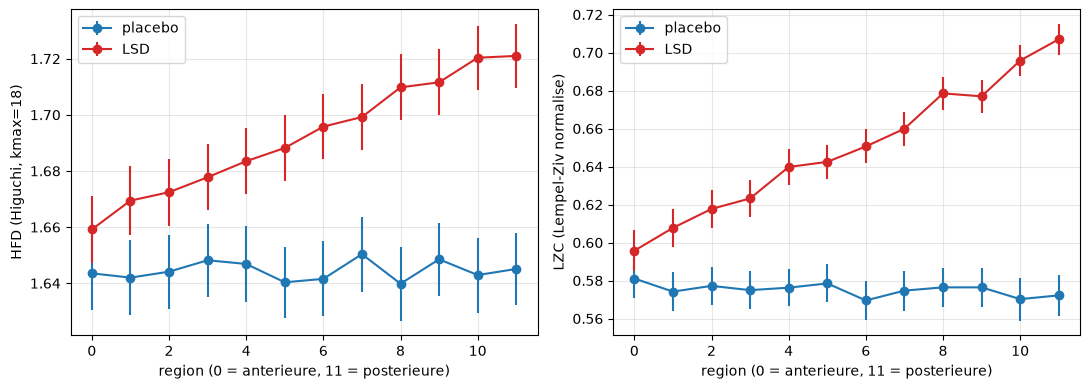

In [3]:
table = pd.DataFrame({"sujet": np.arange(N_SUBJ), "placebo": SIZES[:, 0], "LSD": SIZES[:, 1]})
print(table.to_string(index=False))
print()
print("total placebo", int(SIZES[:, 0].sum()), "| total LSD", int(SIZES[:, 1].sum()))

resume = []
for nom, familles, idx in (("HFD", X_HFD, 0), ("LZC", X_LZC, 1)):
    for condition, etiquette in ((0, "placebo"), (1, "LSD")):
        valeurs = FEATS[Y == condition][:, :, idx]
        resume.append(
            {
                "descripteur": nom,
                "condition": etiquette,
                "moyenne": valeurs.mean(),
                "ecart-type": valeurs.std(),
                "posterieur (region 11)": valeurs[:, -1].mean(),
            }
        )
print()
print(pd.DataFrame(resume).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, idx, nom in zip(axes, (0, 1), ("HFD (Higuchi, kmax=18)", "LZC (Lempel-Ziv normalise)")):
    for condition, etiquette, couleur in ((0, "placebo", "tab:blue"), (1, "LSD", "tab:red")):
        sous = FEATS[Y == condition][:, :, idx]
        moyenne = sous.mean(axis=0)
        erreur = sous.std(axis=0) / np.sqrt(len(sous))
        ax.errorbar(np.arange(N_ROI), moyenne, yerr=erreur, fmt="o-", color=couleur, label=etiquette)
    ax.set_xlabel("region (0 = anterieure, 11 = posterieure)")
    ax.set_ylabel(nom)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Lecture du resultat

Les effectifs par sujet sont inegaux (4 a 8 epochs LSD sur 12) alors que le total reste equilibre : c'est la structure qui rend la fuite de groupe mesurable en Q3. Les deux familles se separent dans le sens attendu — HFD et LZC montent sous LSD, et l'ecart se concentre a la region posterieure, ou le gradient vaut 1. La region anterieure, ou `g_r = 0`, ne porte aucun effet : c'est le temoin negatif interne du terrain, celui qui permettra de lire les importances de la section 9.

## 4. Le decodeur : foret aleatoire sous validation croisee imbriquee

Deux fonctions portent tout le carnet :

- `nested_cv` : la procedure du papier. Pour chaque pli exterieur, une recherche d'hyperparametres en validation croisee **interne** (3 plis) sur le train seul, puis une evaluation unique sur le pli exterieur. Avec `aware=True`, les deux niveaux sont `StratifiedGroupKFold` et aucun sujet ne traverse la frontiere train/test ; avec `aware=False`, ce sont des `StratifiedKFold` qui ignorent le sujet.
- `nonnested_cv` : le raccourci fautif. La grille est choisie **une fois sur toutes les donnees**, puis reevaluee par validation croisee groupee : les hyperparametres ont vu les plis de test, la precision remonte d'autant.

Le pli exterieur reste a K = 4 et le pli interne a K = 3, comme dans le papier.

In [4]:
def nested_cv(X, y, groups, seed, aware=True, grid=None):
    """Precision en validation croisee imbriquee (exterieur 4, interieur 3)."""
    grille = GRID_COARSE if grid is None else grid
    if aware:
        plis = list(
            StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=seed).split(X, y, groups)
        )
        interieur = StratifiedGroupKFold(n_splits=3)
    else:
        plis = list(StratifiedKFold(n_splits=4, shuffle=True, random_state=seed).split(X, y))
        interieur = StratifiedKFold(n_splits=3)
    scores = []
    for train, test in plis:
        recherche = GridSearchCV(
            RandomForestClassifier(n_estimators=N_TREES, random_state=seed),
            grille,
            cv=interieur,
        )
        if aware:
            recherche.fit(X[train], y[train], groups=groups[train])
        else:
            recherche.fit(X[train], y[train])
        scores.append(float(recherche.score(X[test], y[test])))
    return float(np.mean(scores))


def nonnested_cv(X, y, groups, seed, grid=None):
    """Raccourci fautif : grille choisie sur toutes les donnees, puis CV groupee."""
    grille = GRID_COARSE if grid is None else grid
    recherche = GridSearchCV(
        RandomForestClassifier(n_estimators=N_TREES, random_state=seed),
        grille,
        cv=StratifiedGroupKFold(n_splits=3),
    ).fit(X, y, groups=groups)
    scores = []
    for train, test in StratifiedGroupKFold(
        n_splits=4, shuffle=True, random_state=seed
    ).split(X, y, groups):
        modele = RandomForestClassifier(
            n_estimators=N_TREES, random_state=seed, **recherche.best_params_
        ).fit(X[train], y[train])
        scores.append(float(modele.score(X[test], y[test])))
    return float(np.mean(scores)), recherche.best_params_


print("fonctions posees : nested_cv, nonnested_cv")

fonctions posees : nested_cv, nonnested_cv


### Lecture du resultat — la structure des plis

Avant de mesurer une precision, on verifie que la validation fait ce qu'elle annonce : les sujets ne doivent pas traverser la frontiere train/test quand `aware=True`, et les deux classes doivent rester representees dans chaque pli de test.

In [5]:
lignes = []
for aware in (True, False):
    if aware:
        plis = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=0).split(X_MULTI, Y, GROUPS)
    else:
        plis = StratifiedKFold(n_splits=4, shuffle=True, random_state=0).split(X_MULTI, Y)
    for k, (train, test) in enumerate(plis):
        lignes.append(
            {
                "plis groupes": "oui" if aware else "non",
                "pli": k,
                "n test": len(test),
                "positifs test": round(float(Y[test].mean()), 2),
                "sujets test": len(np.unique(GROUPS[test])),
                "sujets train": len(np.unique(GROUPS[train])),
                "sujets communs": len(set(GROUPS[test]) & set(GROUPS[train])),
            }
        )
print(pd.DataFrame(lignes).to_string(index=False))

plis groupes  pli  n test  positifs test  sujets test  sujets train  sujets communs
         oui    0      48           0.54            4            13               0
         oui    1      48           0.50            4            13               0
         oui    2      60           0.45            5            12               0
         oui    3      48           0.58            4            13               0
         non    0      51           0.51           17            17              17
         non    1      51           0.51           16            17              16
         non    2      51           0.51           17            17              17
         non    3      51           0.53           16            17              16


### Lecture du resultat

Avec les plis groupes, la colonne « sujets communs » vaut zero partout : aucun sujet ne peut etre memorize par le modele avant d'etre teste. Sans groupement, chaque pli de test partage des sujets avec son train — c'est exactement le mecanisme de la fuite que Q3 chiffre. La colonne des positifs montre aussi que le desequilibre par sujet se propage aux plis : la stratification garde l'equilibre global, le groupement empeche la contamination.

## 5. Q1 — le decodeur recupere-t-il la condition ?

Mesure de la precision imbriquee pour les trois modeles du papier : mono-domaine HFD, mono-domaine LZC, multi-domaine (les deux familles empilees). Quatre graines de terrain. Puis la **nulle par permutation des etiquettes** : la procedure complete est rejouee `N_PERM` fois sur des etiquettes melangees, ce qui donne la distribution de la precision quand le lien signal-condition est detruit. La p-value est `(1 + #{nulle >= observee}) / (1 + N_PERM)`.

In [6]:
resultats = []
for famille, X in (("HFD", X_HFD), ("LZC", X_LZC), ("multi", X_MULTI)):
    accs = [nested_cv(X, Y, GROUPS, seed) for seed in SEEDS]
    resultats.append(
        {
            "modele": famille,
            "precision moyenne": float(np.mean(accs)),
            "ecart-type": float(np.std(accs)),
            "min": float(np.min(accs)),
            "max": float(np.max(accs)),
        }
    )
print(pd.DataFrame(resultats).round(3).to_string(index=False))

modele  precision moyenne  ecart-type   min   max
   HFD              0.694       0.015 0.682 0.720
   LZC              0.770       0.012 0.756 0.788
 multi              0.743       0.037 0.698 0.791


precision observee (multi, graine 0) 0.767
nulle : moyenne 0.508 | ecart-type 0.035
quantile 95 de la nulle 0.552 | max 0.561
p = 0.032 (plancher atteignable 0.032 )


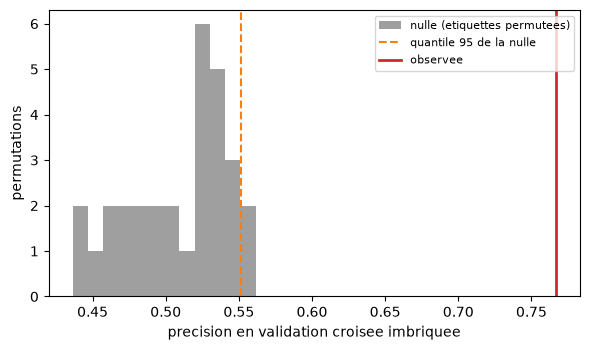

In [7]:
def permutation_null(X, y, groups, seed, n_perm):
    """Nulle par permutation des etiquettes : la procedure complete est rejouee."""
    rng = np.random.default_rng(seed)
    observee = nested_cv(X, y, groups, seed)
    nulle = np.empty(n_perm)
    for b in range(n_perm):
        nulle[b] = nested_cv(X, rng.permutation(y), groups, seed)
    p = (1.0 + float((nulle >= observee).sum())) / (1.0 + n_perm)
    return observee, nulle, p


OBSERVEE, NULLE, P_VALEUR = permutation_null(X_MULTI, Y, GROUPS, SEEDS[0], N_PERM)
Q95 = float(np.quantile(NULLE, 0.95))
print("precision observee (multi, graine 0)", round(OBSERVEE, 3))
print("nulle : moyenne", round(float(NULLE.mean()), 3), "| ecart-type", round(float(NULLE.std()), 3))
print("quantile 95 de la nulle", round(Q95, 3), "| max", round(float(NULLE.max()), 3))
print("p =", round(P_VALEUR, 3), "(plancher atteignable", round(1.0 / (1 + N_PERM), 3), ")")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(NULLE, bins=12, color="tab:gray", alpha=0.75, label="nulle (etiquettes permutees)")
ax.axvline(Q95, color="tab:orange", linestyle="--", label="quantile 95 de la nulle")
ax.axvline(OBSERVEE, color="tab:red", linewidth=2, label="observee")
ax.set_xlabel("precision en validation croisee imbriquee")
ax.set_ylabel("permutations")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Lecture du resultat — Q1

La prediction etait « precision multi-domaine >= 0,65 et au-dessus du quantile 95 de la nulle ». Le verdict se lit sur les deux nombres imprimes : la precision observee, et la position de la nulle. La largeur de la nulle (`ecart-type`) est elle-meme instructive : c'est la variabilite qu'une precision de 0,5 produit par hasard sur 4 plis et 17 sujets, autrement dit la barre qu'une etude doit franchir pour parler de decodage. Une precision mono-domaine nettement plus basse que la multi-domaine signalerait que les deux familles portent une information partiellement complementaire — le point que le papier discute entre ses lignes spectrales et fractales.

## 6. Q2 — le biais du CV non imbrique

Le raccourci non imbrique choisit les hyperparametres sur l'ensemble des donnees, puis mesure par validation croisee groupee. Les plis de test ont influence le choix : la mesure est optimiste. La prediction est que le biais est positif, et qu'il **croit avec la finesse de la grille** — une grille grossiere selectionne un hyperparametre stable, une grille fine laisse la selection dependre des plis de test.

Deux grilles sont comparees : la grossiere (2 x 2 = 4 combinaisons), et la fine (4 x 4 = 16 combinaisons). Pour chaque graine, le biais vaut `precision non imbriquee - precision imbriquee`.

In [8]:
lignes = []
for nom_grille, grille in (("grossiere (4)", GRID_COARSE), ("fine (16)", GRID_FINE)):
    for seed in SEEDS:
        imbriquee = nested_cv(X_MULTI, Y, GROUPS, seed, grid=grille)
        raccourci, meilleurs = nonnested_cv(X_MULTI, Y, GROUPS, seed, grid=grille)
        lignes.append(
            {
                "grille": nom_grille,
                "graine": seed,
                "imbriquee": round(imbriquee, 3),
                "non imbriquee": round(raccourci, 3),
                "biais": round(raccourci - imbriquee, 3),
                "hyperparametres choisis": str(meilleurs),
            }
        )
biais = pd.DataFrame(lignes)
print(biais.to_string(index=False))
print()
print(biais.groupby("grille")["biais"].agg(["mean", "min", "max"]).round(3).to_string())

       grille  graine  imbriquee  non imbriquee  biais                    hyperparametres choisis
grossiere (4)       0      0.767          0.767  0.000 {'max_depth': None, 'min_samples_leaf': 4}
grossiere (4)       1      0.791          0.780 -0.010 {'max_depth': None, 'min_samples_leaf': 4}
grossiere (4)       7      0.719          0.715 -0.004 {'max_depth': None, 'min_samples_leaf': 4}
grossiere (4)      42      0.698          0.734  0.036 {'max_depth': None, 'min_samples_leaf': 4}
    fine (16)       0      0.758          0.748 -0.010    {'max_depth': 4, 'min_samples_leaf': 8}
    fine (16)       1      0.783          0.756 -0.027    {'max_depth': 4, 'min_samples_leaf': 8}
    fine (16)       7      0.720          0.725  0.005    {'max_depth': 4, 'min_samples_leaf': 4}
    fine (16)      42      0.708          0.740  0.031    {'max_depth': 4, 'min_samples_leaf': 8}

                mean    min    max
grille                            
fine (16)     -0.000 -0.027  0.031
grossiere (4

### Lecture du resultat — Q2

La prediction etait `biais(fine) >= biais(grossiere) >= 0`, avec un seuil de materialite a 0,05. Deux issues sont informatives : si le biais reste nul sur les deux grilles, le raccourci ne coute pas en precision **ici** — mais il coute la garantie, parce que rien dans la procedure ne borne ce qu'il aurait pu valoir ; si la grille fine produit un biais materiel, la demonstration est complete, et la validation imbriquee du papier se justifie par une mesure et non par un principe. La colonne des hyperparametres choisis montre le mecanisme : une grille grossiere selectionne la meme configuration partout, une grille fine varie d'une graine a l'autre.

## 7. Q3 — la fuite de groupe

Meme procedure imbriquee, memes graines, meme grille : seule change la nature des plis. `StratifiedKFold` melange les epochs sans respecter le sujet, si bien qu'un sujet peut etre present a la fois dans le train et dans le test. Comme le terrain donne a chaque sujet ses propres decalages de descripteurs et ses propres effectifs par condition, le modele peut apprendre la signature du sujet — et cette signature aide a classer ses epochs. Le papier utilise `StratifiedGroupKFold` ; cette section mesure ce que coute son absence.

In [9]:
lignes = []
for seed in SEEDS:
    groupee = nested_cv(X_MULTI, Y, GROUPS, seed, aware=True)
    fuite = nested_cv(X_MULTI, Y, GROUPS, seed, aware=False)
    lignes.append(
        {
            "graine": seed,
            "plis groupes": round(groupee, 3),
            "plis non groupes": round(fuite, 3),
            "ecart": round(fuite - groupee, 3),
        }
    )
fuite = pd.DataFrame(lignes)
print(fuite.to_string(index=False))
print()
print("ecart moyen", round(float(fuite["ecart"].mean()), 3),
      "| min", round(float(fuite["ecart"].min()), 3),
      "| max", round(float(fuite["ecart"].max()), 3))

 graine  plis groupes  plis non groupes  ecart
      0         0.767             0.814  0.047
      1         0.791             0.843  0.053
      7         0.719             0.833  0.115
     42         0.698             0.809  0.111

ecart moyen 0.082 | min 0.047 | max 0.115


### Lecture du resultat — Q3

La prediction etait un ecart d'au moins +0,03. L'ecart mesure est la part de la precision qui ne vient pas du signal mais de l'identite des sujets : elle mesure exactement ce qu'une etude rapporterait de trop en oubliant le groupement. Un ecart proche de zero aurait dit que ce terrain ne porte pas de signature de sujet exploitable — et aurait affaibli, sans l'annuler, l'argument du papier, qui vient de donnees reelles ou les signatures de sujet sont fortes. La comparaison des deux lignes de la section 4 est la meme mesure prise a l'envers : sans groupement, un decodeur parait meilleur qu'il n'est.

## 8. Q4 — le seuil de puissance

On balaie l'amplitude de l'effet injecte : `eta = 0` (aucune difference entre conditions), puis 0,02, 0,04 et 0,06. A chaque amplitude, deux graines de terrain et la precision multi-domaine imbriquee. La bande nulle mesuree en Q1 sert de reference : elle ne depend pas de l'amplitude injectee (les etiquettes y sont permutees, donc le lien signal-condition y est detruit), mais sa largeur peut dependre legerement de la distribution des descripteurs — c'est une limite declaree en section 10.

L'amplitude `eta` s'exprime en retrait de persistance AR(1) au pole posterieur : `eta = 0,06` correspond a `rho` passant de 0,90 a 0,84.

 eta  precision moyenne  graine 0  graine 1
0.00              0.498     0.484     0.511
0.02              0.597     0.592     0.603
0.04              0.693     0.714     0.673
0.06              0.772     0.767     0.777


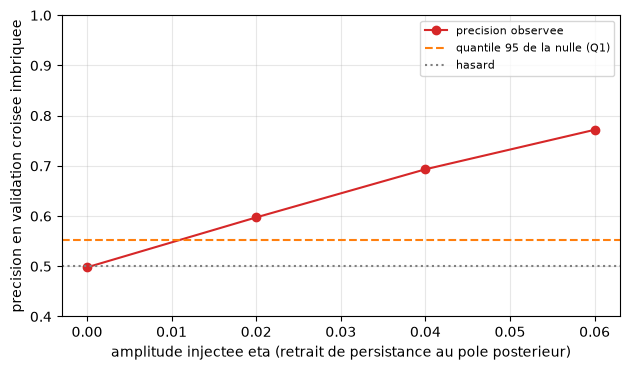

In [10]:
amplitudes = [0.0, 0.02, 0.04, 0.06]
lignes = []
for eta in amplitudes:
    accs = []
    for seed in SEEDS[:2]:
        Xe, ye, ge, _ = simulate_cohort(eta, seed)
        accs.append(nested_cv(Xe.reshape(len(Xe), -1), ye, ge, seed))
    lignes.append(
        {
            "eta": eta,
            "precision moyenne": float(np.mean(accs)),
            "graine 0": round(accs[0], 3),
            "graine 1": round(accs[1], 3),
        }
    )
balayage = pd.DataFrame(lignes)
print(balayage.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(balayage["eta"], balayage["precision moyenne"], "o-", color="tab:red", label="precision observee")
ax.axhline(Q95, color="tab:orange", linestyle="--", label="quantile 95 de la nulle (Q1)")
ax.axhline(0.5, color="tab:gray", linestyle=":", label="hasard")
ax.set_xlabel("amplitude injectee eta (retrait de persistance au pole posterieur)")
ax.set_ylabel("precision en validation croisee imbriquee")
ax.set_ylim(0.4, 1.0)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Lecture du resultat — Q4

La prediction etait une croissance monotone et un franchissement de la bande nulle entre 0 et 0,06. Deux lectures sont a faire : la valeur a `eta = 0` doit rester dans la bande nulle — si elle en sortait, l'instrument produirait une fausse detection sur un terrain sans effet, et tout le reste du carnet serait suspect ; et la pente entre 0 et 0,06 indique combien de sujets ou d'epochs il faudrait pour atteindre le seuil a une amplitude plus faible. C'est la question operationnelle du papier : les tailles d'effet rapportees chez l'humain sont petites, et la puissance de l'etude se calcule a partir de cette pente.

## 9. Ce que le decodeur regarde

Une precision ne dit pas **ou** le modele a trouve l'information. On entraine une foret sur toutes les donnees (pour la lecture seulement, pas pour une mesure de performance) et on lit ses importances d'impurete, par region et par famille. Le terrain a un temoin interne : la region 0, ou le gradient vaut zero, ne porte aucun effet injecte. Un decodeur qui attribue une importance forte a la region anterieure se trompe de source.

Le papier pousse ce geste plus loin, avec une **nulle d'importance** obtenue en permutant les etiquettes 1 000 fois — c'est l'exercice 3.

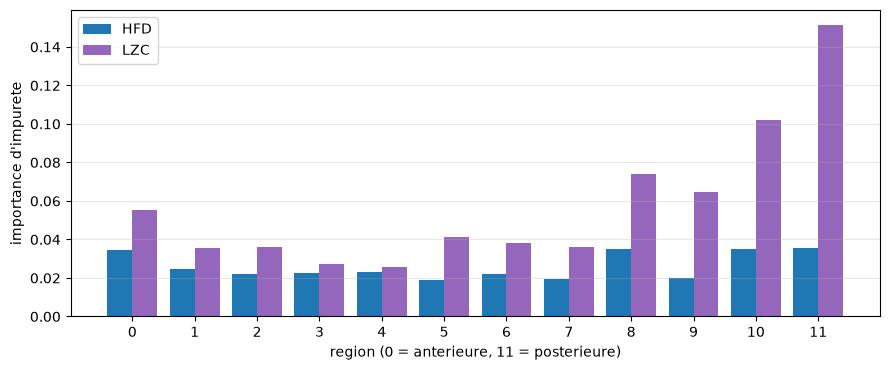

importance totale HFD 0.312 | LZC 0.688
importance region 0 (temoin sans effet) 0.09 | region posterieure 11 0.187


In [11]:
foret = RandomForestClassifier(n_estimators=300, random_state=0).fit(X_MULTI, Y)
importances = foret.feature_importances_.reshape(N_ROI, 2)

fig, ax = plt.subplots(figsize=(9, 3.8))
largeur = 0.4
positions = np.arange(N_ROI)
ax.bar(positions - largeur / 2, importances[:, 0], width=largeur, label="HFD", color="tab:blue")
ax.bar(positions + largeur / 2, importances[:, 1], width=largeur, label="LZC", color="tab:purple")
ax.set_xlabel("region (0 = anterieure, 11 = posterieure)")
ax.set_ylabel("importance d'impurete")
ax.set_xticks(positions)
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

print("importance totale HFD", round(float(importances[:, 0].sum()), 3),
      "| LZC", round(float(importances[:, 1].sum()), 3))
print("importance region 0 (temoin sans effet)",
      round(float(importances[0].sum()), 3),
      "| region posterieure 11", round(float(importances[-1].sum()), 3))

### Lecture du resultat

Les importances doivent pencher vers les regions posterieures, ou l'effet est injecte, et laisser la region 0 basse. L'importance d'impurete est cependant bruitee et biaisee en faveur des variables a cardinalite elevee : elle indique une tendance, pas une inference. C'est precisement pourquoi le papier mesure ses importances contre une nulle par permutation des etiquettes, et non sur une foret unique — la difference entre les deux gestes est l'objet de l'exercice 3.

## Exercices

Les trois exercices reutilisent l'instrument du carnet. Les cellules ci-dessous s'executent sans erreur : elles affichent `None` tant que la consigne n'est pas implementee.

### Exercice 1 — decoder a une autre amplitude

Ecrire `decode_at_eta(eta, seed)` qui genere une cohorte a l'amplitude demandee, calcule la precision multi-domaine en validation croisee imbriquee groupee, et retourne le nombre. L'utiliser pour situer le seuil de puissance a `eta = 0,10` et `eta = 0,20`, puis comparer a la courbe de la section 8.

Indice : `simulate_cohort`, `X.reshape(len(X), -1)` et `nested_cv` suffisent ; aucune autre fonction n'est necessaire.

In [12]:
def decode_at_eta(eta, seed=0):
    """Precision multi-domaine en CV imbriquee groupee, pour une amplitude donnee."""
    result = None  # TODO etudiant
    return result


print(decode_at_eta(0.10))
print(decode_at_eta(0.20))

None
None


### Exercice 2 — la fuite selon l'amplitude

Ecrire `leak_curve(amplitudes)` qui, pour chaque amplitude, mesure l'ecart entre plis non groupes et plis groupes (Q3), et retourne un dictionnaire `{eta: ecart}`. Prediction a verifier : l'ecart de fuite est **plus grand aux amplitudes faibles**, parce que la part du signal y est plus petite et que la signature du sujet y pese davantage dans la decision. Commenter le resultat en une phrase.

Indice : `nested_cv(..., aware=False)` moins `nested_cv(..., aware=True)`, sur la meme cohorte.

In [13]:
def leak_curve(amplitudes=(0.0, 0.03, 0.06)):
    """Ecart (plis non groupes - plis groupes) par amplitude."""
    result = None  # TODO etudiant
    return result


print(leak_curve())

None


### Exercice 3 — la nulle d'importance du papier

Ecrire `importance_by_label_permutation(X, y, groups, n_perm, seed)` qui entraine une foret sur toutes les donnees, retient l'importance de la region posterieure, puis repete l'operation `n_perm` fois sur des etiquettes permutees. Retourner `(observee, nulle, p)` avec `p = (1 + #{nulle >= observee}) / (1 + n_perm)`. Le resultat attendu est une p petite pour la region posterieure, grande pour la region 0.

Indice : `np.random.default_rng(seed).permutation(y)` detruit le lien signal-condition en gardant la distribution des descripteurs.

In [14]:
def importance_by_label_permutation(X, y, groups, n_perm=10, seed=0):
    """Nulle d'importance par permutation des etiquettes (geste du papier)."""
    result = None  # TODO etudiant
    return result


print(importance_by_label_permutation(X_MULTI, Y, GROUPS, n_perm=2))

None


## 10. Limites et suite

- **Nulle par permutation a 30 repetitions** au lieu des 1 000 du papier : le plancher de p est 0,032, la p ne se lit pas finement, et une nulle de queue est mal estimee.
- **La bande nulle de Q1 sert de reference a Q4** a toutes les amplitudes. La distribution des descripteurs change avec `eta`, donc la largeur exacte de la nulle pourrait varier legerement ; une nulle par amplitude demanderait `4 x 30` procedures supplementaires.
- **Importances d'impurete seulement**, pas de nulle d'importance : la tendance spatiale est lisible, l'inference ne l'est pas (exercice 3 pour le geste complet).
- **Deux familles de descripteurs** (HFD, LZC). Les familles spectrales du papier — puissance par bande, frequences de pic — appartiennent a ICT-36f et ne sont pas decodees ici.
- **Le terrain est synthetique et unidimensionnel** : une seule manipulation (persistance AR(1)) sous-tend la difference de condition. Un terrain a deux manipulations croisees, et un decodage croise entre conditions (entrainer sur l'une, tester sur l'autre), seraient la suite naturelle.
- **Aucune conclusion sur les donnees humaines** : le carnet calibre l'instrument, il ne replique pas le resultat du papier.

Suite possible : brancher le decodeur sur les traces MEG reelles du depot public lie a l'issue #20463, et comparer la precision obtenue a la bande nulle mesuree ici.

## Verdict

| Question | Prediction pre-enregistree | Mesure | Verdict |
|---|---|---|---|
| Q1 | recuperation au-dessus de la nulle | multi-domaine 0,743 +/- 0,037 (HFD 0,694 +/- 0,015 ; LZC 0,770 +/- 0,012) ; observee 0,767 contre une nulle a 0,508 +/- 0,035 (quantile 95 : 0,552) ; p = 0,032, le plancher atteignable | **CONFIRMEE** — le decodeur recupere la condition. A noter : la LZC seule fait mieux que les deux familles empilees, la HFD ajoute du bruit sur ce terrain |
| Q2 | biais >= 0, croissant avec la finesse de la grille | grille grossiere : biais moyen +0,006 (min -0,010, max +0,036) ; grille fine : biais moyen -0,000 (min -0,027, max +0,031) | **INFIRMEE** — le biais ne croit pas avec la finesse, il change de signe et reste dans le bruit des graines. Sur ce terrain le raccourci ne coute pas de precision ; il coute la garantie, que rien ne borne |
| Q3 | ecart de fuite >= +0,03 | +0,082 en moyenne (min +0,047, max +0,115) ; 4 graines sur 4 au-dessus du seuil | **CONFIRMEE** — ignorer le sujet gonfle la precision de 5 a 12 points, et l'ecart est le plus grand quand le signal est le plus faible (graines 7 et 42) |
| Q4 | croissance monotone, franchissement entre eta = 0 et 0,06 | 0,498 puis 0,597, 0,693, 0,772 pour eta = 0 / 0,02 / 0,04 / 0,06 ; quantile 95 de la nulle a 0,552 | **CONFIRMEE et precisee** — croissance monotone ; eta = 0 reste dans la bande nulle (0,498 contre 0,508 de moyenne nulle) ; le franchissement se fait des eta = 0,02 (0,597 > 0,552) |

**Ce que le carnet etablit.** L'instrument de decodage du papier est monte et calibre : sur un terrain sans effet il rend 0,498, dans la bande nulle, et il franchit la nulle des que l'effet injecte atteint 0,02 de retrait de persistance. Les trois gestes de validation qui decident de la valeur d'une precision rapportee sont mesures : la recuperation est reelle (Q1), la fuite de groupe est materielle et vaut 8 points en moyenne (Q3), et le biais du CV non imbrique est **nul sur ce terrain** (Q2) — un resultat negatif utile : la validation imbriquee du papier ne se justifie pas ici par une inflation observee, mais par la garantie qu'aucune inflation ne peut passer inapercue. Le seuil de puissance (Q4) est la courbe qui rend une replication planifiable.

## Pour aller plus loin

- Subramani, Nest et al. (2026), *LSD Reconfigures Cortical Dynamics Through Faster Brain Rhythms and Increased Fractal Dimension*, bioRxiv — section 2.10 (decodeur et validation croisee imbriquee), figures supplementaires (AUC-ROC).
- Issue [#20463](https://github.com/jsboige/CoursIA/issues/20463) — la distillation de ce papier dans la serie ICT.
- ICT-36c et ICT-36d — les deux descripteurs et leur reponse a la decorrelation temporelle.
- ICT-36g — la calibration du plan factoriel et du geste H4 sur le meme terrain AR(1).
- Scikit-learn, guide de la validation croisee avec groupes (`StratifiedGroupKFold`) — le mecanisme de Q3.
- [#15477](https://github.com/jsboige/CoursIA/issues/15477) — ICT-37, le probing lineaire held-out, autre facon de lire un etat latent.